# Wine Dataset Clustering: K-means and Hierarchical Clustering

## Notebook purpose

This notebook reproduces the workflow in the accompanying `wine_clustering.py` file. 

The analysis uses the UCI Wine dataset and performs preprocessing, exploratory analysis, PCA, K-means clustering, hierarchical clustering, validation, cluster profiling, statistical tests, and report generation.

**Important design rule:** the `class` column is separated from the chemical measurements before modelling. It is not used for preprocessing, PCA, fitting clusters, or selecting the number of clusters. It is used only in the optional external-validation section, after clustering has been completed.

## Before running

Place `wine.data` in the notebook's working folder. Running the final reporting section creates a `wine_results` folder containing the saved tables, charts, scaled data, and PDF report.

Run the cells from top to bottom because later cells use variables created earlier.

##  Imports and notebook setup

The imports below are the same dependencies used by the Python script:

- **Path and warnings** handle file locations and warning display.
- **NumPy and pandas** support numerical operations and tabular data.
- **Matplotlib and Seaborn** create charts.
- **SciPy** provides hierarchical clustering, distance calculations, and statistical tests.
- **scikit-learn** provides imputation, scaling, PCA, K-means, and validation metrics.
- **PdfPages** combines the saved charts and summary into a PDF report.

The script suppresses `FutureWarning` messages. This does not change the clustering calculations.

In [111]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from scipy.stats import f_oneway, kruskal

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
# A compact PDF report is created from the key charts and findings.
from matplotlib.backends.backend_pdf import PdfPages

warnings.filterwarnings("ignore", category=FutureWarning)

## 1. General settings and dataset loading

Set up file locations, configuration, and dataset columns. The script creates the output folder if it does not already exist and fixes the random seed at 42 for reproducible K-means/PCA operations. It then checks for `wine.data`, reads the file using the 14 specified column names, and separates the class labels from the 13 chemical features. The final prints inspect the feature data, types, and missing values.

### Project paths and reproducibility

The notebook uses the current working directory when `__file__` is unavailable (as is normal in Jupyter). `DATA_FILE` therefore expects `wine.data` in that working directory. `OUTPUT_FOLDER` is created automatically.

In [112]:
BASE_FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FILE = BASE_FOLDER / "wine.data"
OUTPUT_FOLDER = BASE_FOLDER / "wine_results"
OUTPUT_FOLDER.mkdir(exist_ok=True)

RANDOM_STATE = 42

### Column definitions, loading, and label separation

The list defines the dataset's first column as `class` and the remaining columns as chemical attributes. `true_labels` is retained separately; `features` contains only the chemical measurements used in the unsupervised workflow.

In [113]:
column_names = [
    "class",
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280_od315",
    "proline",
]

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "The file 'wine.data' was not found. Keep wine.data in the same "
        "folder as this Python file or notebook."
    )

wine_data = pd.read_csv(DATA_FILE, header=None, names=column_names)

# The first column contains class labels. It is separated before modelling.
true_labels = wine_data["class"].copy()
features = wine_data.drop(columns=["class"]).copy()

### Initial dataset inspection

These displays report the number of samples and attributes, show the first ten feature rows, list data types, and count missing values in each chemical attribute.

In [114]:
print("DATASET OVERVIEW")
print("Number of rows:", features.shape[0])
print("Number of chemical attributes:", features.shape[1])
print("\nFirst 10 rows of the chemical attributes:")
print(features.head(10).to_string(index=False))

print("\nData types:")
print(features.dtypes)

print("\nMissing values in each feature:")
print(features.isnull().sum())

DATASET OVERVIEW
Number of rows: 178
Number of chemical attributes: 13

First 10 rows of the chemical attributes:
 alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  od280_od315  proline
   14.23        1.71 2.43               15.6        127           2.80        3.06                  0.28             2.29             5.64 1.04         3.92     1065
   13.20        1.78 2.14               11.2        100           2.65        2.76                  0.26             1.28             4.38 1.05         3.40     1050
   13.16        2.36 2.67               18.6        101           2.80        3.24                  0.30             2.81             5.68 1.03         3.17     1185
   14.37        1.95 2.50               16.8        113           3.85        3.49                  0.24             2.18             7.80 0.86         3.45     1480
   13.24        2.59 2.87               21.0        118 

## 2. Part A: Missing values and standardisation

Prepare the chemical measurements for analysis. Median imputation fills missing entries, and standardisation puts all features on a comparable scale. The scaled feature table is also saved as a CSV file.

### Median imputation and standardisation

`SimpleImputer(strategy="median")` replaces missing values in each column with that column's median. `StandardScaler` then centres each feature around zero and scales it to unit variance. The original feature names and row indices are retained in the resulting DataFrames.

In [115]:
imputer = SimpleImputer(strategy="median")
features_imputed = pd.DataFrame(
    imputer.fit_transform(features),
    columns=features.columns,
    index=features.index,
)

scaler = StandardScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(features_imputed),
    columns=features.columns,
    index=features.index,
)

scaled_file = OUTPUT_FOLDER / "wine_scaled_features.csv"
scaled_features.to_csv(scaled_file, index=False)

print("\nMissing values after imputation:", int(features_imputed.isnull().sum().sum()))
print("Scaled dataset saved to:", scaled_file)


Missing values after imputation: 0
Scaled dataset saved to: d:\Notes\year 3 sem 1\Ai\group 3\wine_results\wine_scaled_features.csv


## 3. Part B: First exploratory data analysis

Explore selected chemical attributes and determine how much dimensionality reduction is possible. The section prints descriptive statistics, plots six feature distributions, fits PCA to the standardised features, and visualises individual and cumulative explained variance. The number of components is selected to retain at least 95% of the variance.

### Descriptive statistics and feature distributions

The six selected attributes are summarised using count, mean, standard deviation, minimum, quartiles, and maximum. The six histograms show each attribute's distribution; the KDE curve provides a smoothed view of its shape.


DESCRIPTIVE STATISTICS
       alcohol  malic_acid      ash  flavanoids  color_intensity   proline
count  178.000     178.000  178.000     178.000          178.000   178.000
mean    13.001       2.336    2.367       2.029            5.058   746.893
std      0.812       1.117    0.274       0.999            2.318   314.907
min     11.030       0.740    1.360       0.340            1.280   278.000
25%     12.362       1.602    2.210       1.205            3.220   500.500
50%     13.050       1.865    2.360       2.135            4.690   673.500
75%     13.678       3.082    2.558       2.875            6.200   985.000
max     14.830       5.800    3.230       5.080           13.000  1680.000


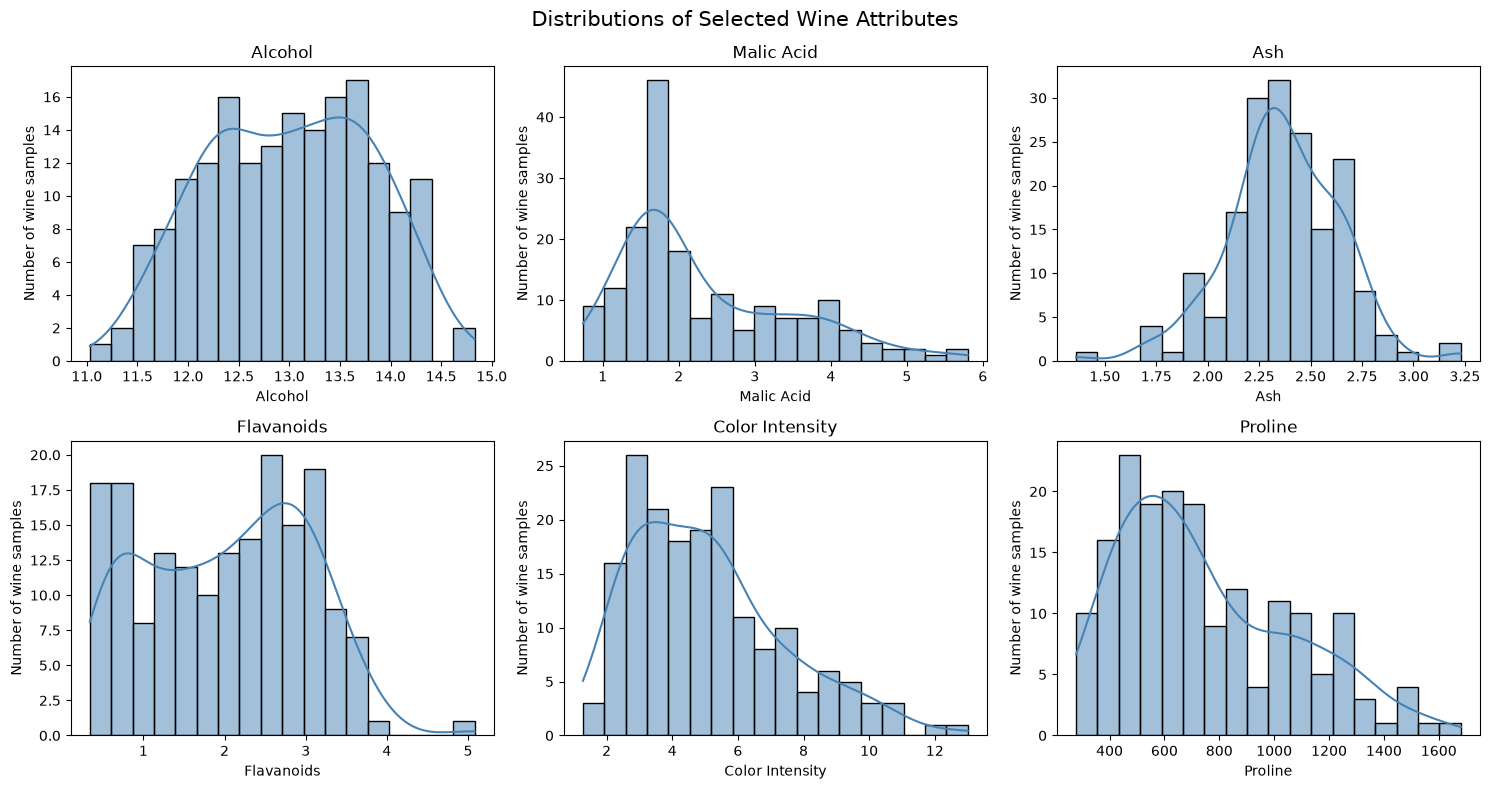

In [116]:
selected_features = [
    "alcohol",
    "malic_acid",
    "ash",
    "flavanoids",
    "color_intensity",
    "proline",
]

print("\nDESCRIPTIVE STATISTICS")
print(features_imputed[selected_features].describe().round(3))

# Histograms for six selected chemical attributes.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature_name in zip(axes.flat, selected_features):
    sns.histplot(
        features_imputed[feature_name],
        kde=True,
        bins=18,
        color="steelblue",
        ax=ax,
    )
    ax.set_title(feature_name.replace("_", " ").title())
    ax.set_xlabel(feature_name.replace("_", " ").title())
    ax.set_ylabel("Number of wine samples")

fig.suptitle("Distributions of Selected Wine Attributes", fontsize=15)
fig.tight_layout()
histogram_file = OUTPUT_FOLDER / "feature_histograms.png"
fig.savefig(histogram_file, dpi=300, bbox_inches="tight")
plt.show()

### PCA explained variance and component selection

PCA is first fitted without reducing the number of components so that the variance explained by every component can be examined. The scree plot shows individual and cumulative variance, while the horizontal line marks the 95% target. `np.argmax` finds the first component position where cumulative variance reaches that target.

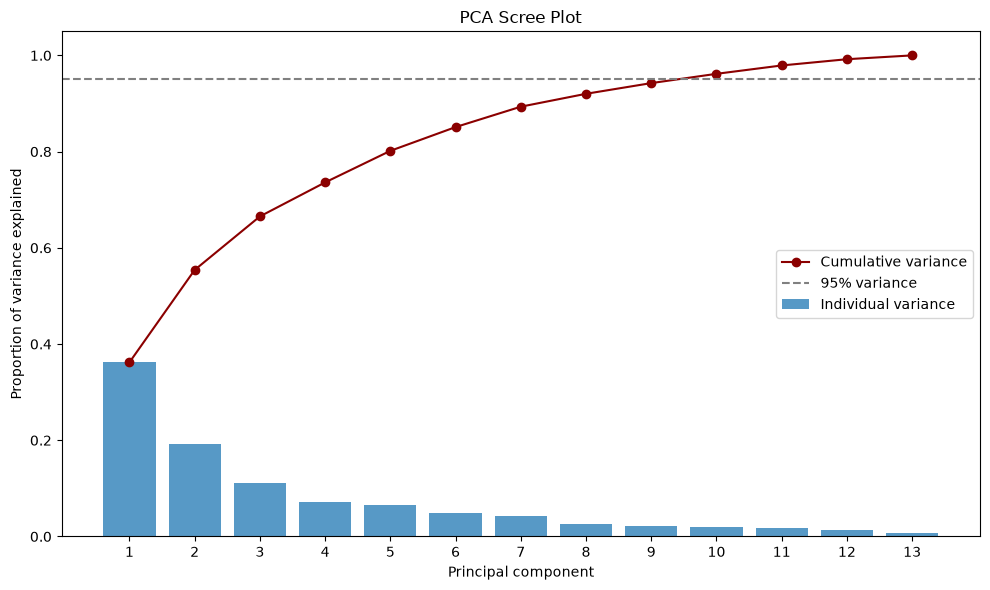


Number of PCA components needed to retain at least 95% variance: 10
Variance retained: 0.9617


In [117]:
pca_all = PCA()
pca_all.fit(scaled_features)

explained_variance = pca_all.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

fig, ax = plt.subplots(figsize=(10, 6))
component_numbers = np.arange(1, len(explained_variance) + 1)
ax.bar(component_numbers, explained_variance, alpha=0.75, label="Individual variance")
ax.plot(
    component_numbers,
    cumulative_variance,
    marker="o",
    color="darkred",
    label="Cumulative variance",
)
ax.axhline(0.95, linestyle="--", color="grey", label="95% variance")
ax.set_xlabel("Principal component")
ax.set_ylabel("Proportion of variance explained")
ax.set_title("PCA Scree Plot")
ax.set_xticks(component_numbers)
ax.legend()
fig.tight_layout()
scree_file = OUTPUT_FOLDER / "pca_scree_plot.png"
fig.savefig(scree_file, dpi=300, bbox_inches="tight")
plt.show()

number_of_components = int(np.argmax(cumulative_variance >= 0.95) + 1)
print("\nNumber of PCA components needed to retain at least 95% variance:",
      number_of_components)
print("Variance retained:", round(cumulative_variance[number_of_components - 1], 4))

## 4. Part C: Feature engineering and dimensionality reduction

Transform the 13 standardised chemical attributes into the reduced PCA representation. The component count comes from the 95% variance rule in the previous section. The resulting DataFrame uses names such as `PC1`, `PC2`, and so on, and becomes the feature space for clustering.

### Fit PCA and create the reduced feature table

`fit_transform` learns the principal-component directions and projects each wine sample into the reduced space. The printed dimensions make the reduction from the original feature count explicit.

In [118]:
pca_reduced = PCA(n_components=number_of_components, random_state=RANDOM_STATE)
pca_features = pca_reduced.fit_transform(scaled_features)

pca_columns = [f"PC{i + 1}" for i in range(number_of_components)]
pca_feature_data = pd.DataFrame(
    pca_features,
    columns=pca_columns,
    index=features.index,
)

print("\nOriginal number of dimensions:", scaled_features.shape[1])
print("Number of dimensions after PCA:", pca_feature_data.shape[1])


Original number of dimensions: 13
Number of dimensions after PCA: 10


## 5. Part D: K-means clustering and internal validation

Fit K-means for each candidate cluster count from 2 through 8. For every value of k, the script records silhouette, Davies–Bouldin, Calinski–Harabasz, and inertia. It selects the model with the highest silhouette score and plots the three validation metrics.

### Fit and evaluate candidate K-means models

The loop trains a separate K-means model for each k. `random_state=42` supports repeatability and `n_init=20` runs multiple initial-centre choices. The validation metrics describe cluster separation/compactness, while inertia is the within-cluster sum of squared distances.

In [119]:
k_values = range(2, 9)
kmeans_results = []
kmeans_models = {}

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20,
    )
    cluster_assignments = model.fit_predict(pca_feature_data)
    kmeans_models[k] = model

    kmeans_results.append({
        "k": k,
        "silhouette": silhouette_score(pca_feature_data, cluster_assignments),
        "davies_bouldin": davies_bouldin_score(pca_feature_data, cluster_assignments),
        "calinski_harabasz": calinski_harabasz_score(
            pca_feature_data, cluster_assignments
        ),
        "inertia": model.inertia_,
    })

kmeans_results = pd.DataFrame(kmeans_results)
print("\nK-MEANS VALIDATION RESULTS")
print(kmeans_results.round(4).to_string(index=False))


K-MEANS VALIDATION RESULTS
 k  silhouette  davies_bouldin  calinski_harabasz   inertia
 2      0.2697          1.4818            73.4276 1570.2540
 3      0.2987          1.3363            76.1796 1189.6391
 4      0.2733          1.7405            60.5892 1088.3898
 5      0.2473          1.6303            50.7635 1023.7589
 6      0.2054          1.8266            45.1886  961.8541
 7      0.2091          1.6409            41.9328  900.4754
 8      0.1629          1.6879            39.5544  846.5626


### Select the preferred model and compare metrics

The script chooses the k with the maximum silhouette score. Davies–Bouldin and Calinski–Harabasz are retained as supporting measures. The three-panel chart shows how those metrics change across the tested k values.


Selected number of clusters: 3
Selection reason: it has the highest silhouette score among k = 2 to 8.


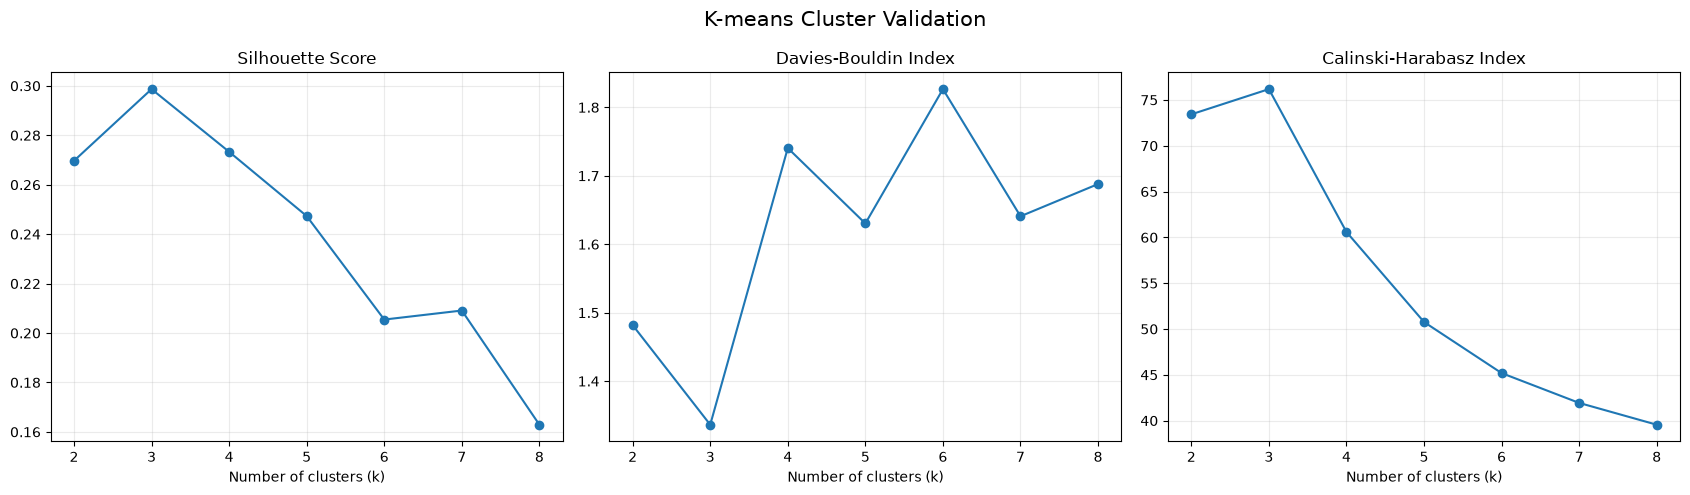

In [120]:
# The highest silhouette score is used as the main selection rule.
# Davies-Bouldin and Calinski-Harabasz are considered as supporting measures.
best_k = int(
    kmeans_results.loc[kmeans_results["silhouette"].idxmax(), "k"]
)
best_kmeans = kmeans_models[best_k]
kmeans_clusters = best_kmeans.labels_

print("\nSelected number of clusters:", best_k)
print("Selection reason: it has the highest silhouette score among k = 2 to 8.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
metric_columns = [
    ("silhouette", "Silhouette Score"),
    ("davies_bouldin", "Davies-Bouldin Index"),
    ("calinski_harabasz", "Calinski-Harabasz Index"),
]
for ax, (column, title) in zip(axes, metric_columns):
    ax.plot(kmeans_results["k"], kmeans_results[column], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(k_values))
    ax.grid(alpha=0.25)
fig.suptitle("K-means Cluster Validation", fontsize=15)
fig.tight_layout()
kmeans_metrics_file = OUTPUT_FOLDER / "kmeans_validation_metrics.png"
fig.savefig(kmeans_metrics_file, dpi=300, bbox_inches="tight")
plt.show()

## 6. Hierarchical clustering: Ward and Average linkage

Perform agglomerative hierarchical clustering using Ward and Average linkage on the PCA features. The script calculates Euclidean pairwise distances, builds both linkage trees, evaluates their cophenetic correlations, plots dendrograms, and cuts each tree to the K-means-selected cluster count for a descriptive comparison.

### Build the Ward and Average linkage trees

`pdist` calculates pairwise Euclidean distances. `linkage` then constructs hierarchical trees using Ward's method and Average linkage. `cophenet` compares the distances represented by each tree with the original pairwise distances; a higher correlation indicates a more faithful representation.

In [121]:
distance_matrix = pdist(pca_feature_data, metric="euclidean")

ward_linkage = linkage(pca_feature_data, method="ward", metric="euclidean")
average_linkage = linkage(pca_feature_data, method="average", metric="euclidean")

ward_cophenetic, _ = cophenet(ward_linkage, distance_matrix)
average_cophenetic, _ = cophenet(average_linkage, distance_matrix)

print("\nHIERARCHICAL CLUSTERING")
print("Ward cophenetic correlation:", round(ward_cophenetic, 4))
print("Average cophenetic correlation:", round(average_cophenetic, 4))


HIERARCHICAL CLUSTERING
Ward cophenetic correlation: 0.6637
Average cophenetic correlation: 0.7615


### Visualise the dendrograms

Each dendrogram shows how samples or previously formed groups are progressively merged. The vertical axis is linkage distance. Labels are hidden to keep the plots readable for the full dataset.

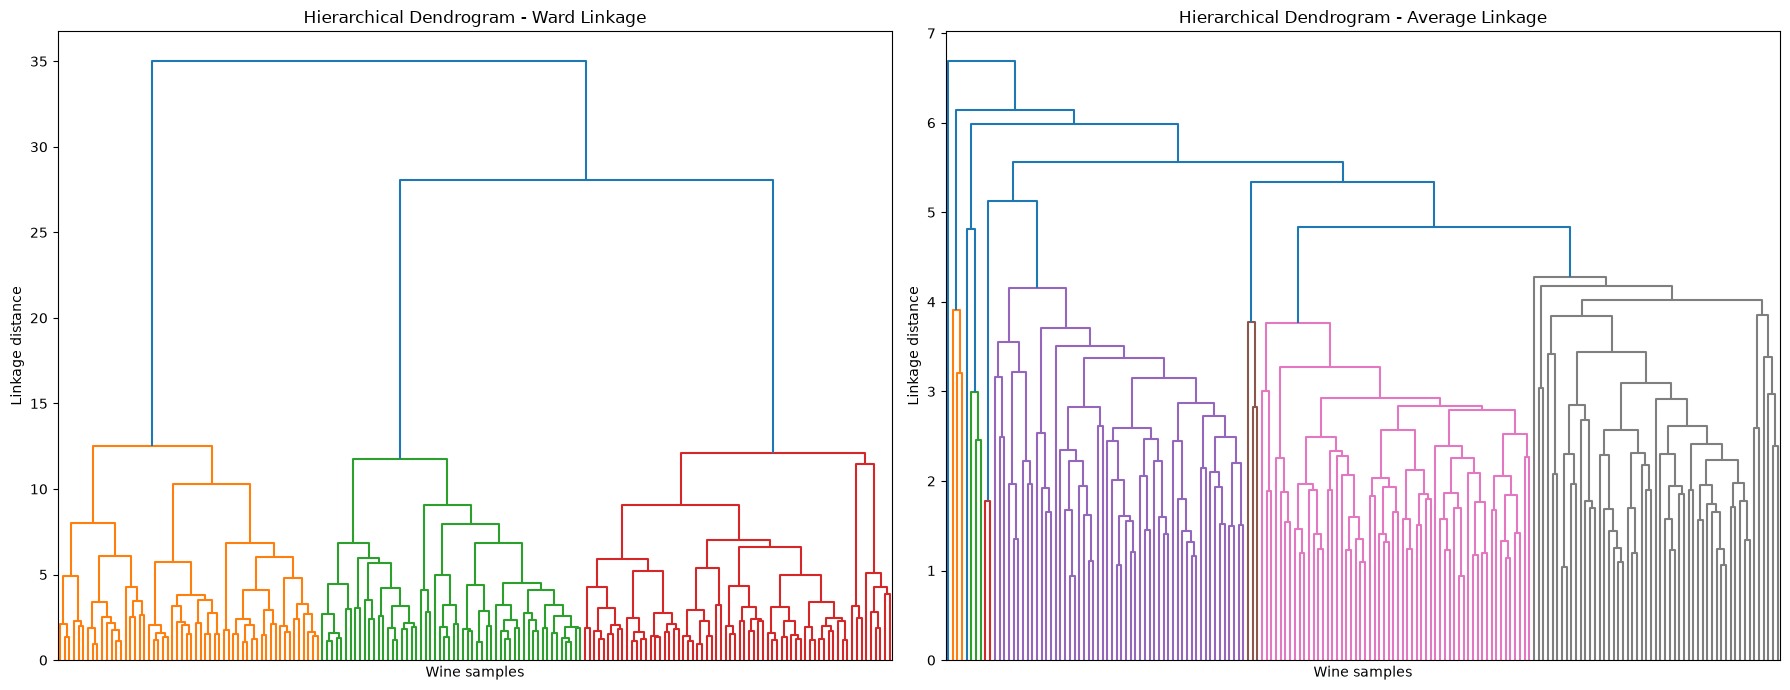

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
dendrogram(
    ward_linkage,
    ax=axes[0],
    no_labels=True,
    color_threshold=None,
)
axes[0].set_title("Hierarchical Dendrogram - Ward Linkage")
axes[0].set_xlabel("Wine samples")
axes[0].set_ylabel("Linkage distance")

dendrogram(
    average_linkage,
    ax=axes[1],
    no_labels=True,
    color_threshold=None,
)
axes[1].set_title("Hierarchical Dendrogram - Average Linkage")
axes[1].set_xlabel("Wine samples")
axes[1].set_ylabel("Linkage distance")

fig.tight_layout()
dendrogram_file = OUTPUT_FOLDER / "hierarchical_dendrograms.png"
fig.savefig(dendrogram_file, dpi=300, bbox_inches="tight")
plt.show()

### Cut the trees and evaluate hierarchical clusters

`fcluster` forms flat cluster assignments using the same maximum cluster count selected for K-means. Silhouette, Davies–Bouldin, and Calinski–Harabasz scores are then calculated for Ward and Average assignments.

In [123]:
# Use the K-means-selected cluster count for a fair descriptive comparison.
ward_clusters = fcluster(ward_linkage, t=best_k, criterion="maxclust") - 1
average_clusters = fcluster(average_linkage, t=best_k, criterion="maxclust") - 1

hierarchical_results = []
for method_name, assignments in [
    ("Ward", ward_clusters),
    ("Average", average_clusters),
]:
    hierarchical_results.append({
        "method": method_name,
        "clusters": len(np.unique(assignments)),
        "silhouette": silhouette_score(pca_feature_data, assignments),
        "davies_bouldin": davies_bouldin_score(pca_feature_data, assignments),
        "calinski_harabasz": calinski_harabasz_score(
            pca_feature_data, assignments
        ),
    })

hierarchical_results = pd.DataFrame(hierarchical_results)
print("\nHIERARCHICAL CLUSTER VALIDATION")
print(hierarchical_results.round(4).to_string(index=False))


HIERARCHICAL CLUSTER VALIDATION
 method  clusters  silhouette  davies_bouldin  calinski_harabasz
   Ward         3      0.2840          1.3441            72.1409
Average         3      0.1493          0.9749             4.1078


## 7. Optional external validation using the true class labels

Compare the completed cluster assignments with the dataset's true class labels. This is explicitly optional external validation and occurs only after the unsupervised modelling decisions have been made. Adjusted Rand Index and Normalized Mutual Information quantify agreement between cluster assignments and known labels.

### External validation after clustering

The table reports ARI and NMI for K-means, Ward, and Average. These metrics use `true_labels` only at this final evaluation stage; they do not feed back into preprocessing, PCA, model fitting, or cluster selection.

In [124]:
# The labels are used only here, after all model choices have been made.
external_validation = pd.DataFrame([
    {
        "method": "K-means",
        "adjusted_rand_index": adjusted_rand_score(true_labels, kmeans_clusters),
        "normalized_mutual_information": normalized_mutual_info_score(
            true_labels, kmeans_clusters
        ),
    },
    {
        "method": "Ward",
        "adjusted_rand_index": adjusted_rand_score(true_labels, ward_clusters),
        "normalized_mutual_information": normalized_mutual_info_score(
            true_labels, ward_clusters
        ),
    },
    {
        "method": "Average",
        "adjusted_rand_index": adjusted_rand_score(true_labels, average_clusters),
        "normalized_mutual_information": normalized_mutual_info_score(
            true_labels, average_clusters
        ),
    },
])

print("\nOPTIONAL EXTERNAL VALIDATION")
print(external_validation.round(4).to_string(index=False))


OPTIONAL EXTERNAL VALIDATION
 method  adjusted_rand_index  normalized_mutual_information
K-means               0.8975                         0.8759
   Ward               0.7587                         0.7624
Average              -0.0054                         0.0184


## 8. Part E: Cluster profiles and centroids in original units

Interpret the K-means clusters in the original chemical-feature units. The script transforms K-means centres back from PCA space through standardised space into original units, calculates average feature profiles and sample counts, and plots the clusters using the first two principal components.

### Recover centroids and calculate cluster profiles

K-means centres are initially expressed in PCA coordinates. `inverse_transform` first maps them back to the standardised feature space, and the scaler's inverse transformation returns values to the original measurement units. Cluster profiles are calculated as means of the imputed original features, with a sample count for each cluster.

In [125]:
# K-means was trained in PCA space. Its cluster centres are transformed
# back to the standardised feature space, then returned to original units.
centres_in_scaled_units = pca_reduced.inverse_transform(best_kmeans.cluster_centers_)
centres_in_original_units = scaler.inverse_transform(centres_in_scaled_units)

centroid_table = pd.DataFrame(
    centres_in_original_units,
    columns=features.columns,
)
centroid_table.index = [f"Cluster {i}" for i in range(best_k)]
centroid_table.index.name = "Cluster"

print("\nK-MEANS CLUSTER CENTROIDS IN ORIGINAL UNITS")
print(centroid_table.round(3).to_string())

# Cluster profiles use the original measured values.
clustered_features = features_imputed.copy()
clustered_features["cluster"] = kmeans_clusters

cluster_profiles = clustered_features.groupby("cluster")[features.columns].mean()
cluster_sizes = clustered_features["cluster"].value_counts().sort_index()
cluster_profiles.insert(0, "sample_count", cluster_sizes)

print("\nK-MEANS CLUSTER PROFILES")
print(cluster_profiles.round(3).to_string())


K-MEANS CLUSTER CENTROIDS IN ORIGINAL UNITS
           alcohol  malic_acid    ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity    hue  od280_od315   proline
Cluster                                                                                                                                                                             
Cluster 0   12.248       1.899  2.229             20.087     92.763          2.247       2.057                 0.358            1.621            2.980  1.063        2.805   512.460
Cluster 1   13.133       3.310  2.415             21.269     98.719          1.670       0.860                 0.453            1.141            7.239  0.691        1.693   620.576
Cluster 2   13.682       1.994  2.471             17.415    107.899          2.860       2.962                 0.291            1.929            5.443  1.066        3.165  1096.576

K-MEANS CLUSTER PROFILES
         sample_count  a

### Plot cluster assignments in two PCA dimensions

A separate two-component PCA projection is created for visualisation. The scatter plot colours each sample by its K-means assignment; axis labels include the percentage of variance explained by each plotted component.

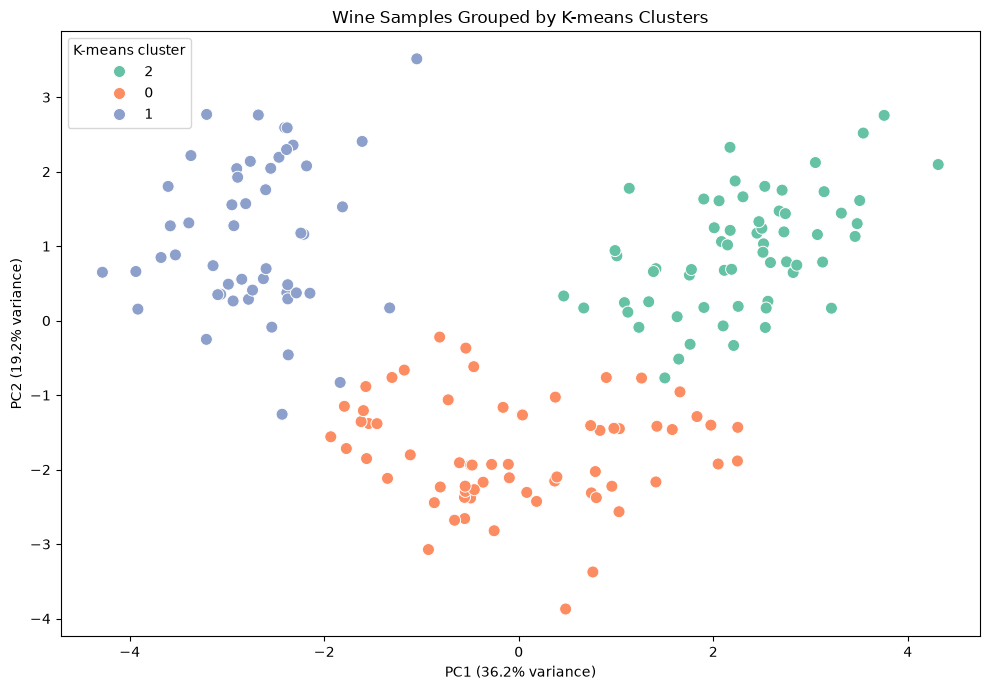

In [126]:
# PCA scatter plot using the first two principal components.
pca_for_plot = PCA(n_components=2, random_state=RANDOM_STATE)
pca_plot_values = pca_for_plot.fit_transform(scaled_features)

pca_plot_data = pd.DataFrame({
    "PC1": pca_plot_values[:, 0],
    "PC2": pca_plot_values[:, 1],
    "cluster": kmeans_clusters.astype(str),
})

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=pca_plot_data,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=75,
    ax=ax,
)
ax.set_title("Wine Samples Grouped by K-means Clusters")
ax.set_xlabel(f"PC1 ({pca_for_plot.explained_variance_ratio_[0] * 100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_for_plot.explained_variance_ratio_[1] * 100:.1f}% variance)")
ax.legend(title="K-means cluster")
fig.tight_layout()
pca_cluster_file = OUTPUT_FOLDER / "pca_clusters.png"
fig.savefig(pca_cluster_file, dpi=300, bbox_inches="tight")
plt.show()

## 9. Statistical inference: alcohol and flavanoids

Test whether alcohol and flavanoids differ across the K-means clusters. The code calculates ANOVA and Kruskal–Wallis tests, alongside eta-squared and epsilon-squared effect sizes. It then plots standardised cluster profiles as a heatmap and compares the effect sizes in a bar chart.

### Define effect-size calculations and run statistical tests

`calculate_eta_squared` computes the proportion of total variation associated with between-cluster differences for one-way ANOVA. `calculate_epsilon_squared` calculates the Kruskal–Wallis effect-size estimate. The loop applies ANOVA and Kruskal–Wallis to the alcohol and flavanoids values grouped by K-means cluster.

In [127]:
def calculate_eta_squared(groups, all_values):
    """Calculate one-way ANOVA eta-squared effect size."""
    overall_mean = np.mean(all_values)
    between_group_sum = sum(
        len(group) * (np.mean(group) - overall_mean) ** 2
        for group in groups
    )
    total_sum = np.sum((all_values - overall_mean) ** 2)
    return between_group_sum / total_sum if total_sum > 0 else np.nan


def calculate_epsilon_squared(kruskal_statistic, sample_size, group_count):
    """Calculate an effect size for the Kruskal-Wallis test."""
    if sample_size <= group_count:
        return np.nan
    value = (kruskal_statistic - group_count + 1) / (sample_size - group_count)
    return max(0.0, value)


statistical_results = []

for feature_name in ["alcohol", "flavanoids"]:
    groups = [
        clustered_features.loc[
            clustered_features["cluster"] == cluster_number, feature_name
        ].to_numpy()
        for cluster_number in range(best_k)
    ]

    anova_statistic, anova_p_value = f_oneway(*groups)
    kruskal_statistic, kruskal_p_value = kruskal(*groups)

    all_values = clustered_features[feature_name].to_numpy()
    eta_squared = calculate_eta_squared(groups, all_values)
    epsilon_squared = calculate_epsilon_squared(
        kruskal_statistic,
        len(all_values),
        len(groups),
    )

    statistical_results.append({
        "feature": feature_name,
        "anova_f": anova_statistic,
        "anova_p_value": anova_p_value,
        "eta_squared": eta_squared,
        "kruskal_h": kruskal_statistic,
        "kruskal_p_value": kruskal_p_value,
        "epsilon_squared": epsilon_squared,
    })

statistical_results = pd.DataFrame(statistical_results)

print("\nSTATISTICAL TESTS BETWEEN K-MEANS CLUSTERS")
print(statistical_results.to_string(
    index=False,
    formatters={
        "anova_f": "{:.3f}".format,
        "anova_p_value": "{:.3e}".format,
        "eta_squared": "{:.3f}".format,
        "kruskal_h": "{:.3f}".format,
        "kruskal_p_value": "{:.3e}".format,
        "epsilon_squared": "{:.3f}".format,
    },
))


STATISTICAL TESTS BETWEEN K-MEANS CLUSTERS
   feature anova_f anova_p_value eta_squared kruskal_h kruskal_p_value epsilon_squared
   alcohol 113.166     2.879e-32       0.564   101.947       7.286e-23           0.571
flavanoids 271.590     2.215e-54       0.756   133.285       1.142e-29           0.750


### Prepare and display the cluster-profile heatmap

Five selected features are converted to z-scores using their dataset means and standard deviations. The cluster column is then used to calculate each cluster's mean standardised profile. Heatmap values show deviations from the overall dataset mean in standard-deviation units.

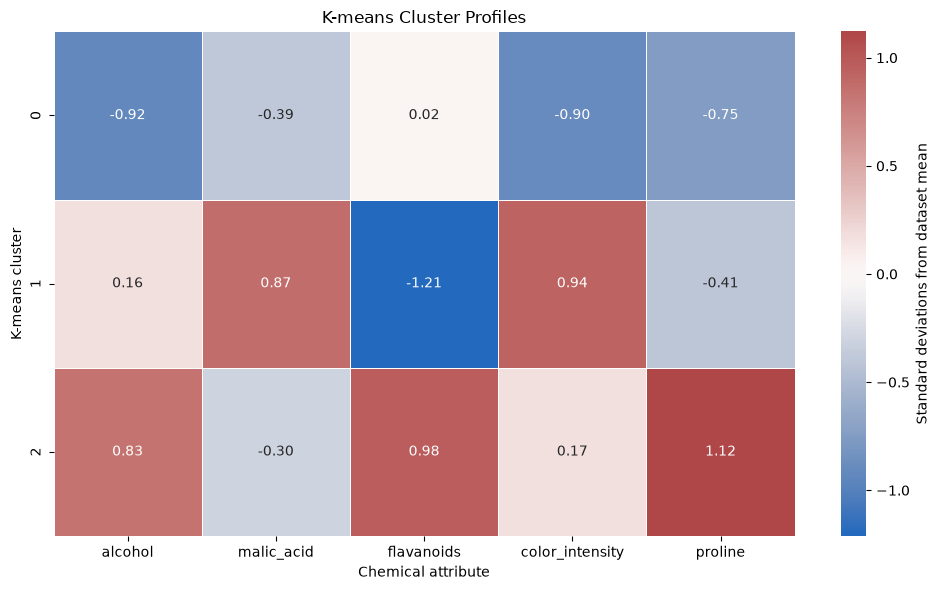

In [128]:
# Prepare data for the heatmap (Z-scores / standardized values) using a dedicated variable name
heatmap_selected_features = ["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline"]

heatmap_scaled_features = (features[heatmap_selected_features] - features[heatmap_selected_features].mean()) / features[heatmap_selected_features].std()
heatmap_scaled_features["kmeans_cluster"] = kmeans_clusters

cluster_profiles_scaled = heatmap_scaled_features.groupby("kmeans_cluster").mean()

# Plotting the Heatmap with explicit figure handles and show()
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    cluster_profiles_scaled, 
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    center=0, 
    linewidths=0.5,
    cbar_kws={'label': 'Standard deviations from dataset mean'},
    ax=ax
)
ax.set_title("K-means Cluster Profiles")
ax.set_xlabel("Chemical attribute")
ax.set_ylabel("K-means cluster")
fig.tight_layout()

heatmap_file = OUTPUT_FOLDER / "cluster_profiles_heatmap.png"
fig.savefig(heatmap_file, dpi=300, bbox_inches="tight")
plt.show()

### Compare effect sizes and interpret the tests

The grouped bars compare eta-squared and epsilon-squared for alcohol and flavanoids. The printed guide states that a p-value below 0.05 suggests at least one cluster differs, while effect sizes describe the magnitude of the difference.

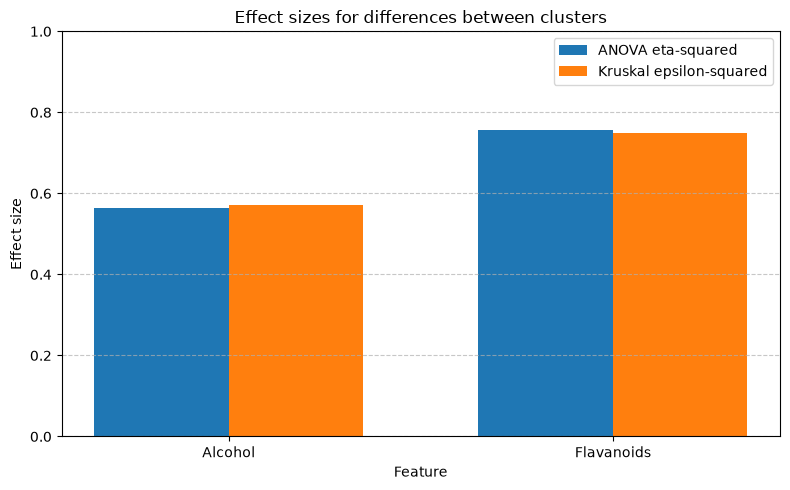


INTERPRETATION GUIDE
A p-value below 0.05 suggests that at least one cluster differs.
Eta-squared and epsilon-squared describe the size of the difference.
A small p-value does not by itself mean the difference is large.


In [129]:
# Plotting Effect Sizes Bar Chart with explicit figure handles and show()
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(statistical_results["feature"]))
width = 0.35

ax.bar(x - width/2, statistical_results["eta_squared"], width, label="ANOVA eta-squared")
ax.bar(x + width/2, statistical_results["epsilon_squared"], width, label="Kruskal epsilon-squared")

ax.set_xlabel("Feature")
ax.set_ylabel("Effect size")
ax.set_title("Effect sizes for differences between clusters")
ax.set_xticks(x)
ax.set_xticklabels(statistical_results["feature"].str.capitalize())
ax.set_ylim(0, 1.0)
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.7)
fig.tight_layout()

bar_chart_file = OUTPUT_FOLDER / "effect_sizes_bar_chart.png"
fig.savefig(bar_chart_file, dpi=300, bbox_inches="tight")
plt.show()


print("\nINTERPRETATION GUIDE")
print("A p-value below 0.05 suggests that at least one cluster differs.")
print("Eta-squared and epsilon-squared describe the size of the difference.")
print("A small p-value does not by itself mean the difference is large.")

## 10. Part F: Save results and create a simple analysis report

Save the principal result tables and sample-level assignments as CSV files. The final block creates a multi-page PDF report: a summary page followed by the charts generated throughout the analysis. It then prints the locations of the output folder, PDF report, and scaled dataset.

### Save result tables and sample assignments

The script exports K-means and hierarchical validation, external validation, centroids, cluster profiles, statistical test results, and each sample's assignments under the three clustering methods.

In [130]:
# Save the main result tables.
kmeans_results.to_csv(OUTPUT_FOLDER / "kmeans_validation_results.csv", index=False)
hierarchical_results.to_csv(
    OUTPUT_FOLDER / "hierarchical_validation_results.csv", index=False
)
external_validation.to_csv(
    OUTPUT_FOLDER / "external_validation_results.csv", index=False
)
centroid_table.to_csv(OUTPUT_FOLDER / "cluster_centroids_original_units.csv")
cluster_profiles.to_csv(OUTPUT_FOLDER / "cluster_profiles.csv")
statistical_results.to_csv(
    OUTPUT_FOLDER / "statistical_test_results.csv", index=False
)

# Save sample-level cluster assignments separately.
sample_assignments = pd.DataFrame({
    "sample_number": np.arange(1, len(features) + 1),
    "kmeans_cluster": kmeans_clusters,
    "ward_cluster": ward_clusters,
    "average_cluster": average_clusters,
})
sample_assignments.to_csv(
    OUTPUT_FOLDER / "sample_cluster_assignments.csv", index=False
)

### Assemble the PDF report and finish

The first PDF page contains dataset details, the PCA variance retained, the selected k, validation tables, and interpretation guidance. The remaining pages embed the saved histograms, scree plot, validation chart, dendrograms, PCA cluster plot, heatmap, and effect-size chart.

In [131]:
# A compact PDF report is created from the key charts and findings.

pdf_file = OUTPUT_FOLDER / "wine_clustering_report.pdf"

with PdfPages(pdf_file) as pdf:
    # Summary page
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.94, "Wine Dataset Clustering Report", fontsize=20, weight="bold")
    summary_lines = [
        f"Dataset: UCI Wine dataset ({len(features)} samples, {features.shape[1]} attributes)",
        "Class labels were excluded from model fitting and cluster selection.",
        f"PCA retained {number_of_components} components and "
        f"{cumulative_variance[number_of_components - 1] * 100:.2f}% of variance.",
        f"Selected K-means cluster count: {best_k}",
        "",
        "K-means validation:",
        kmeans_results.round(4).to_string(index=False),
        "",
        "Hierarchical cophenetic correlations:",
        f"Ward: {ward_cophenetic:.4f}",
        f"Average: {average_cophenetic:.4f}",
        "",
        "External validation (labels used only after clustering):",
        external_validation.round(4).to_string(index=False),
        "",
        "Statistical tests:",
        statistical_results.to_string(
            index=False,
            formatters={
                "anova_p_value": "{:.3e}".format,
                "kruskal_p_value": "{:.3e}".format,
            },
        ),
        "",
        "Interpretation:",
        "Silhouette is better when higher. Davies-Bouldin is better when lower.",
        "Calinski-Harabasz is better when higher. Cophenetic correlation measures",
        "how faithfully a dendrogram represents the pairwise distances.",
        "ANOVA and Kruskal-Wallis test whether feature values differ across clusters.",
    ]
    fig.text(
        0.08, 0.89, "\n".join(summary_lines),
        fontsize=8.5, va="top", family="monospace"
    )
    plt.axis("off")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    for image_file in [
        histogram_file,
        scree_file,
        kmeans_metrics_file,
        dendrogram_file,
        pca_cluster_file,
        heatmap_file,
        bar_chart_file,
    ]:
        image = plt.imread(image_file)
        fig, ax = plt.subplots(figsize=(11.7, 8.27))
        ax.imshow(image)
        ax.axis("off")
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print("\nANALYSIS COMPLETE")
print("All output files have been saved in:", OUTPUT_FOLDER)
print("PDF report:", pdf_file)
print("Scaled dataset:", scaled_file)


ANALYSIS COMPLETE
All output files have been saved in: d:\Notes\year 3 sem 1\Ai\group 3\wine_results
PDF report: d:\Notes\year 3 sem 1\Ai\group 3\wine_results\wine_clustering_report.pdf
Scaled dataset: d:\Notes\year 3 sem 1\Ai\group 3\wine_results\wine_scaled_features.csv


## 11. Presentation & Reflection (Part F – 10 points)

This section brings together the main decisions made during the analysis. It addresses two presentation questions:

1. **How did dimensionality reduction using PCA influence the clustering decisions?**
2. **How suitable were hierarchical clustering and K-means for this dataset, and what trade-offs do they involve?**

The discussion uses the PCA and clustering results already produced above. It does not fit new models or change any cluster assignments.

### 11.1 How PCA influenced the clustering decisions

The original dataset contains **13 chemical attributes** for each wine sample. These attributes are measured on different scales. Standardisation was therefore performed before PCA so that attributes with larger numerical ranges would not automatically dominate the analysis.

PCA (Principal Component Analysis) creates new variables called **principal components**. Each component is a combination of the original attributes. The first component captures as much of the variation in the data as possible; each following component captures as much of the remaining variation as possible while being uncorrelated with the earlier components.

In this analysis, the number of components was selected using a **95% cumulative explained-variance threshold**. This means the retained components collectively preserve at least 95% of the variation represented by the standardised features. The remaining variation is not retained in the reduced representation.

**Why this mattered for clustering:**

- K-means, Ward linkage, and Average linkage were all applied to `pca_feature_data`, not directly to the original 13 attributes.
- PCA reduced the number of dimensions used to calculate distances and form clusters.
- Combining correlated information into principal components can reduce redundancy and make the clustering space more compact.
- The reduction also involves a trade-off: some information is discarded, so the resulting clusters may differ from clusters formed using all 13 standardised attributes.
- PCA does not use the wine class labels. The labels remain separate until the optional external validation section.

Run the next cell to display the exact number of retained components and the variance preserved in this analysis.

In [132]:
# Summarise the effect of PCA on the feature space.
pca_influence_summary = pd.DataFrame({
    "measure": [
        "Original standardised features",
        "Retained principal components",
        "Variance retained",
        "Variance not retained",
    ],
    "value": [
        scaled_features.shape[1],
        pca_feature_data.shape[1],
        f"{cumulative_variance[number_of_components - 1] * 100:.2f}%",
        f"{(1 - cumulative_variance[number_of_components - 1]) * 100:.2f}%",
    ],
})

print("PCA DIMENSIONALITY-REDUCTION SUMMARY")
print(pca_influence_summary.to_string(index=False))

print("\nPCA'S ROLE IN THE CLUSTERING DECISION")
print(
    f"All three clustering approaches used {pca_feature_data.shape[1]} "
    f"principal components instead of the original {scaled_features.shape[1]} features."
)
print(
    f"These components retained "
    f"{cumulative_variance[number_of_components - 1] * 100:.2f}% "
    "of the variance in the standardised dataset."
)
print(
    f"K-means then selected k = {best_k} using the highest silhouette score "
    "among the tested values from 2 to 8."
)

PCA DIMENSIONALITY-REDUCTION SUMMARY
                       measure  value
Original standardised features     13
 Retained principal components     10
             Variance retained 96.17%
         Variance not retained  3.83%

PCA'S ROLE IN THE CLUSTERING DECISION
All three clustering approaches used 10 principal components instead of the original 13 features.
These components retained 96.17% of the variance in the standardised dataset.
K-means then selected k = 3 using the highest silhouette score among the tested values from 2 to 8.


### 11.2 Hierarchical clustering versus K-means: suitability and trade-offs

Both methods are useful for discovering groups in the Wine dataset, but they approach the problem differently.

**K-means**

- **How it works:** K-means assigns each sample to the nearest cluster centre and repeatedly updates the centres until the assignments stabilise.
- **Strengths:** It is relatively fast, straightforward to run for several candidate values of `k`, and produces cluster centres that can be used to describe typical feature values in each group.
- **Limitations:** The number of clusters must be chosen before fitting. Results can also depend on initial centre placement, which is why this script fixes `random_state=42` and uses `n_init=20`. K-means is most comfortable with compact, roughly spherical groups and can be affected by outliers.
- **In this analysis:** Candidate values from 2 to 8 were tested. The value with the highest silhouette score was selected, while Davies–Bouldin and Calinski–Harabasz scores provided supporting evidence.

**Hierarchical clustering**

- **How it works:** Agglomerative hierarchical clustering begins with individual samples and progressively merges the closest samples or groups. The resulting tree is displayed as a dendrogram.
- **Strengths:** A dendrogram makes the nested merging structure visible. It allows the analyst to inspect relationships at different levels before cutting the tree into a chosen number of clusters.
- **Limitations:** It does not naturally provide the same simple, repeatedly updated centroid model as K-means. Pairwise-distance and linkage calculations can become computationally expensive as dataset size grows. The result also depends on the selected linkage rule and distance measure.
- **In this analysis:** Ward and Average linkage were both tested using Euclidean distances. Their dendrograms and cophenetic correlations were examined, and both trees were cut using the K-means-selected cluster count to make the descriptive comparison consistent.

**The main trade-off:** K-means is a practical choice when a defined number of clusters and efficient assignment are important. Hierarchical clustering is valuable when the analyst also wants to understand how samples and groups relate at different levels. For this dataset, which contains 178 samples, both approaches are practical to compare; the validation results should guide the conclusion rather than assuming that one method is automatically superior.

The next cell places the internal validation results side by side. Remember: a **higher silhouette score** and **higher Calinski–Harabasz score** are generally preferred, while a **lower Davies–Bouldin index** is generally preferred. Cophenetic correlation evaluates how faithfully a hierarchical tree represents the original pairwise distances; it is not directly interchangeable with the three cluster-validation scores.

In [133]:
# Compare the selected K-means result with the two hierarchical methods.
kmeans_selected_row = kmeans_results.loc[
    kmeans_results["k"] == best_k,
    ["silhouette", "davies_bouldin", "calinski_harabasz"],
].iloc[0]

presentation_comparison = pd.DataFrame([
    {
        "method": "K-means",
        "clusters": best_k,
        "silhouette": kmeans_selected_row["silhouette"],
        "davies_bouldin": kmeans_selected_row["davies_bouldin"],
        "calinski_harabasz": kmeans_selected_row["calinski_harabasz"],
        "cophenetic_correlation": np.nan,
    },
    {
        "method": "Hierarchical - Ward",
        "clusters": int(hierarchical_results.loc[
            hierarchical_results["method"] == "Ward", "clusters"
        ].iloc[0]),
        "silhouette": hierarchical_results.loc[
            hierarchical_results["method"] == "Ward", "silhouette"
        ].iloc[0],
        "davies_bouldin": hierarchical_results.loc[
            hierarchical_results["method"] == "Ward", "davies_bouldin"
        ].iloc[0],
        "calinski_harabasz": hierarchical_results.loc[
            hierarchical_results["method"] == "Ward", "calinski_harabasz"
        ].iloc[0],
        "cophenetic_correlation": ward_cophenetic,
    },
    {
        "method": "Hierarchical - Average",
        "clusters": int(hierarchical_results.loc[
            hierarchical_results["method"] == "Average", "clusters"
        ].iloc[0]),
        "silhouette": hierarchical_results.loc[
            hierarchical_results["method"] == "Average", "silhouette"
        ].iloc[0],
        "davies_bouldin": hierarchical_results.loc[
            hierarchical_results["method"] == "Average", "davies_bouldin"
        ].iloc[0],
        "calinski_harabasz": hierarchical_results.loc[
            hierarchical_results["method"] == "Average", "calinski_harabasz"
        ].iloc[0],
        "cophenetic_correlation": average_cophenetic,
    },
])

print("CLUSTERING METHOD COMPARISON")
print(presentation_comparison.round(4).to_string(index=False))

print("\nPRESENTATION POINTS")
print(f"K-means selected cluster count: {best_k}")
print(
    "K-means selection basis: highest silhouette score among the tested "
    "candidate values (k = 2 to 8)."
)
print(
    "Hierarchical methods: Ward and Average linkage were both cut to the "
    "same target cluster count for comparison."
)
print(
    "Cophenetic correlations: Ward = "
    f"{ward_cophenetic:.4f}; Average = {average_cophenetic:.4f}."
)

CLUSTERING METHOD COMPARISON
                method  clusters  silhouette  davies_bouldin  calinski_harabasz  cophenetic_correlation
               K-means         3      0.2987          1.3363            76.1796                     NaN
   Hierarchical - Ward         3      0.2840          1.3441            72.1409                  0.6637
Hierarchical - Average         3      0.1493          0.9749             4.1078                  0.7615

PRESENTATION POINTS
K-means selected cluster count: 3
K-means selection basis: highest silhouette score among the tested candidate values (k = 2 to 8).
Hierarchical methods: Ward and Average linkage were both cut to the same target cluster count for comparison.
Cophenetic correlations: Ward = 0.6637; Average = 0.7615.


### 11.3 Reflection and conclusion

Use the two output tables and the charts above to support a short, evidence-based conclusion.

When presenting the influence of PCA, state the original number of features, the number of principal components retained, and the percentage of variance preserved. Explain that the reduced PCA representation became the common input to all three clustering approaches. This is important because the clustering comparison was made in the same transformed feature space.

When comparing the clustering methods, refer to the actual validation scores rather than simply saying that one method performed better. Explain the practical difference between K-means' centroid-based assignments and the hierarchical methods' tree-based structure. Also acknowledge that the hierarchical comparison used the cluster count selected by K-means; this makes the comparison consistent in cluster count, but it does not mean hierarchical clustering independently selected that number.

**Overall reflection:** PCA made the clustering task more compact while retaining at least 95% of the standardised feature variance. K-means provided a systematic way to select a cluster count using internal validation, while Ward and Average linkage provided alternative group structures and dendrograms. The most suitable method should be justified using the observed validation results, the dendrograms, and the purpose of the analysis—not by the algorithm name alone.